# FGM Research in Nigeria (2015–2026)
Exploratory Data Analysis EDA| Code Alpha Task 2

## Project Overview

Female Genital Mutilation (FGM) remains a significant public health and social concern in Nigeria. This project explores scholarly publications on FGM in Nigeria between 2015 and 2026, examining publication trends, geographical distribution and research methodologies.

Using data collected from PubMed, the analysis seeks to identify patterns in research output and understand how research attention is distributed across the country.

## Research Questions

This analysis is guided by four research questions:

1. How has FGM research publication output in Nigeria changed between 2015 and 2026?

2. Which geopolitical zones in Nigeria receive the most research attention?

3. What research methodologies are most commonly used in FGM-related studies in Nigeria?

4. What are the major themes explored in FGM-related studies in Nigeria?

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# Display all columns when viewing dataframes
pd.set_option("display.max_columns", None)

# Load the dataset
df = pd.read_csv(
    "cleaneddata.csv",
    dtype={"pmid": "string"}
)

# Display the first five records
df.head()

,pmid,title,authors,publication_year,journal,abstract,doi,article_url,screening_decision,study_location,research_type
0,30692824,"Female genital mutilation; culture, religion, ...",Olalekan Olugbenga Awolola; N A Ilupeju,2019,Tzu chi medical journal,Female genital mutilation (FGM) is a form of v...,10.4103/tcmj.tcmj_127_18,https://pubmed.ncbi.nlm.nih.gov/30692824/,Include,Not applicable,Literature review
1,38616797,Effect of Female Genital Mutilation on Sexual ...,Promise Ifechukwu Okpara; Serap Tekbaş,2024,International journal of sexual health : offic...,"Objective: Female genital mutilation, which ha...",10.1080/19317611.2024.2328717,https://pubmed.ncbi.nlm.nih.gov/38616797/,Include,South-West Nigeria,Quantitative - cross-sectional
2,33172757,Female genital mutilation (FGM): Is it still a...,Reham Nafad Elbendary; Dina Ali Shokry; Wessam...,2021,Forensic science international,Female Genital Mutilation (FGM) is one of thos...,10.1016/j.forsciint.2020.110574,https://pubmed.ncbi.nlm.nih.gov/33172757/,Exclude,Not verified,Not classified
3,27707452,Female genital mutilation: a systematic review...,Emmanuel Kabengele Mpinga; Aurélie Macias; Jen...,2016,Global health action,Global efforts to end female genital mutilatio...,10.3402/gha.v9.31489,https://pubmed.ncbi.nlm.nih.gov/27707452/,Exclude,Not verified,Not classified
4,40193370,The determinants of female genital mutilation ...,Charles Echezona Nzelu; Uche Maureen Nzelu; Am...,2025,PLOS global public health,Female Genital Mutilation/Circumcision (FGM/C)...,10.1371/journal.pgph.0004413,https://pubmed.ncbi.nlm.nih.gov/40193370/,Include,National,Quantitative - secondary survey analysis


In [ ]:
# Task 2: Investigate inconsistent categories and possible duplicates
print("\n--- RESEARCH TYPE LABELS ---")
print(df["research_type"].value_counts(dropna=False).to_string())

print("\n--- STUDY LOCATION LABELS ---")
print(df["study_location"].value_counts(dropna=False).to_string())

print("\n--- SCREENING DECISIONS ---")
print(df["screening_decision"].value_counts(dropna=False).to_string())

print("\n--- POSSIBLE DUPLICATE TITLES ---")
title_clean = df["title"].str.strip().str.lower()
duplicate_titles = df[title_clean.duplicated(keep=False)]

if duplicate_titles.empty:
    print("No duplicate titles found.")
else:
    print(duplicate_titles[["pmid", "title", "publication_year"]].sort_values("title").to_string(index=False))

# Prepare the eligible dataset
eda_df = df[
    df["screening_decision"]
    .astype("string")
    .str.strip()
    .str.casefold()
    .isin(["include", "included"])
].copy()

eda_df["publication_year"] = pd.to_numeric(eda_df["publication_year"], errors="coerce")
print("\nNumber of eligible articles:", len(eda_df))

## Research Question 1

**How has FGM research publication output in Nigeria changed between 2015 and 2026?**

### Hypothesis 1

FGM research publications in Nigeria have increased over the study period.

To examine this hypothesis, the number of included publications will be counted for each year between 2015 and 2026.

A line chart will be used to show how publication output has changed over time.

In [ ]:
# Count publications per year
yearly_puablications = (
    eda_df.groupby("publication_year")
    .size()
    .reindex(range(2015, 2027), fill_value=0)
)

# Display annual publication counts
yearly_publications = yearly_publications.astype(int)

Annual publication output:


,Number of Publications
publication_year,
2015,2
2016,1
2017,3
2018,2
2019,5
2020,3
2021,6
2022,6
2023,3


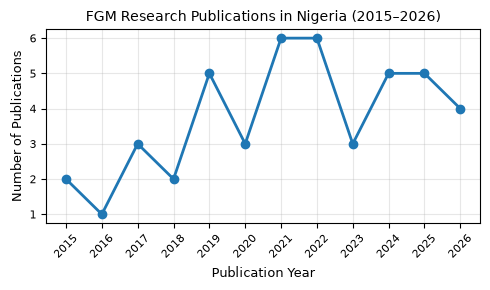

In [13]:
# Publication charts
print("Annual publication output:")
display(yearly_publications.to_frame(name="Number of Publications"))

plt.figure(figsize=(5, 3))

plt.plot(
    yearly_publications.index,
    yearly_publications.values,
    marker="o",
    linewidth=2
)

plt.title("FGM Research Publications in Nigeria (2015–2026)", fontsize=10)
plt.xlabel("Publication Year", fontsize=9)
plt.ylabel("Number of Publications", fontsize=9)

plt.xticks(range(2015, 2027), rotation=45, fontsize=8)
plt.yticks(fontsize=8)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

The line chart shows the annual number of included FGM research publications between 2015 and 2026.

The pattern can be used to identify years with relatively high or low publication output and to examine whether research activity has generally increased over the period.

The 2026 publication count should be interpreted cautiously because the year is not yet complete. Therefore, it should not be directly compared with the completed years as though they cover the same period.

## Research Question 2

**Which geopolitical zones in Nigeria receive the most research attention?**

### Hypothesis 2

FGM research publications are geographically concentrated in certain geopolitical zones rather than being evenly distributed across Nigeria.

The study locations will be examined to identify the geopolitical zones explicitly represented in the dataset.

National studies, multi-country studies, studies with unspecified locations, and records labelled only as "Northern Nigeria" will not be forced into a specific geopolitical zone.

In [14]:
# Count the study location categories
location_counts = eda_df["study_location"].value_counts()

print("Study location distribution:")
display(location_counts.to_frame(name="Number of Studies"))

Study location distribution:


,Number of Studies
study_location,
National,16
South-Eastern Nigeria,10
South-West Nigeria,9
North-Central Nigeria,2
Multi-country,2
Northern Nigeria,2
Nigeria (locality not specified),2
Not applicable,1
Nationwide (Multi-country),1


In [15]:
# Map only locations that explicitly identify a geopolitical zone
zone_mapping = {
    "South-Eastern Nigeria": "South-East",
    "South-West Nigeria": "South-West",
    "North-Central Nigeria": "North-Central"
}

# Create a new column for explicit geopolitical zone assignments
eda_df["geopolitical_zone"] = (
    eda_df["study_location"].map(zone_mapping)
)

# Count studies assigned to explicitly identified zones
zone_counts = (
    eda_df["geopolitical_zone"]
    .dropna()
    .value_counts()
)

print("Studies with explicitly identified geopolitical zones:")
display(zone_counts.to_frame(name="Number of Studies"))

# Show locations that were not assigned to a specific zone
unassigned_locations = eda_df[
    eda_df["geopolitical_zone"].isna()
]["study_location"].value_counts()

print("\nLocations not assigned to a specific geopolitical zone:")
display(unassigned_locations.to_frame(name="Number of Studies"))

Studies with explicitly identified geopolitical zones:


,Number of Studies
geopolitical_zone,
South-East,10
South-West,9
North-Central,2



Locations not assigned to a specific geopolitical zone:


,Number of Studies
study_location,
National,16
Multi-country,2
Northern Nigeria,2
Nigeria (locality not specified),2
Not applicable,1
Nationwide (Multi-country),1


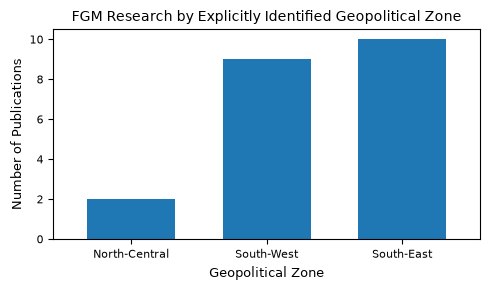

In [16]:
plt.figure(figsize=(5, 3))

zone_counts.sort_values().plot(
    kind="bar",
    width=0.65
)

plt.title(
    "FGM Research by Explicitly Identified Geopolitical Zone",
    fontsize=10
)

plt.xlabel("Geopolitical Zone", fontsize=9)
plt.ylabel("Number of Publications", fontsize=9)

plt.xticks(rotation=0, fontsize=8)
plt.yticks(fontsize=8)

plt.tight_layout()
plt.show()

### Interpretation

The chart compares the number of included studies whose locations explicitly identify a geopolitical zone.

The distribution should be interpreted as the geographical representation of the included publications, not as a measure of FGM prevalence or the actual burden of FGM in each zone.

Some records identify a specific zone, while others refer to Nigeria nationally, multiple countries, or locations that are not sufficiently specific.

For example, "Northern Nigeria" cannot automatically be classified as North-Central, North-East, or North-West. These records are therefore retained separately rather than assigned to a zone without supporting information.

## Research Question 3

**What research methodologies are most commonly used in FGM-related studies in Nigeria?**

### Hypothesis 3

Quantitative research methodologies are the most commonly used approaches in FGM-related studies in Nigeria.

The research type column will be examined to identify the methodological approaches used in the included studies.

For easier comparison, the original research type descriptions will be grouped into broader categories: quantitative, qualitative, mixed methods, and literature review.

In [17]:
def group_research_type(research_type):

    research_type = str(research_type).strip().casefold()

    # Check mixed methods first so they are not classified
    # as only quantitative or qualitative
    if (
        "mixed" in research_type
        or "quantitative/qualitative" in research_type
        or "qualitative/quantitative" in research_type
        or ("survey" in research_type and "fgd" in research_type)
    ):
        return "Mixed methods"

    elif "literature review" in research_type:
        return "Literature review"

    elif "qualitative" in research_type:
        return "Qualitative"

    elif "quantitative" in research_type:
        return "Quantitative"

    else:
        return "Needs manual review"


# Apply the grouping function
eda_df["methodology_group"] = (
    eda_df["research_type"].apply(group_research_type)
)

# Count each methodology group
methodology_counts = (
    eda_df["methodology_group"]
    .value_counts()
)

print("Research methodology distribution:")
display(
    methodology_counts.to_frame(
        name="Number of Studies"
    )
)

Research methodology distribution:


,Number of Studies
methodology_group,
Quantitative,32
Qualitative,10
Mixed methods,2
Literature review,1


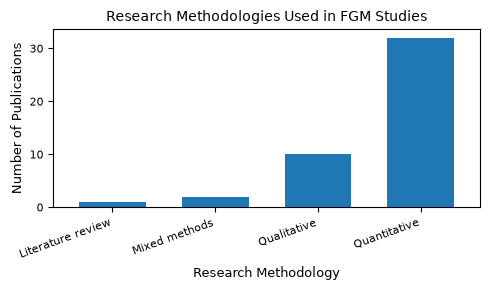

In [18]:
plt.figure(figsize=(5, 3))

methodology_counts.sort_values().plot(
    kind="bar",
    width=0.65
)

plt.title("Research Methodologies Used in FGM Studies", fontsize=10)
plt.xlabel("Research Methodology", fontsize=9)
plt.ylabel("Number of Publications", fontsize=9)

plt.xticks(rotation=20, ha="right", fontsize=8)
plt.yticks(fontsize=8)

plt.tight_layout()
plt.show()

### Interpretation

The chart shows the distribution of research methodologies among the included FGM publications.

The methodology categories make it easier to compare the use of quantitative, qualitative, mixed-methods, and literature-based approaches.

The results will indicate whether quantitative research is the most frequently represented methodology in the dataset.

The original research type descriptions should also be reviewed to ensure that the grouping accurately reflects each study's methodology.

## Research Question 4

**What are the major themes explored in FGM-related studies in Nigeria?**

### Hypothesis 4

FGM research in Nigeria focuses more on socio-cultural factors and the prevention of FGM than on other research themes.

The titles and abstracts of the included publications will be examined to identify recurring research themes.

Since the dataset does not contain a dedicated research theme column, themes will initially be identified using keyword-based classification.

A publication may be assigned to more than one theme where its title or abstract addresses multiple areas.

The resulting classifications are provisional and should be checked against the full abstracts before drawing final conclusions.

In [19]:
# Define keyword patterns for the research themes.
# A study may match more than one theme.

theme_keywords = {
    "Socio-cultural factors": [
        r"\bcultur",
        r"\btradition",
        r"\breligio",
        r"\bbelief",
        r"\battitude",
        r"\bperception",
        r"\bsocial norm",
        r"\bsocial rejection",
        r"\bsubjective norm",
        r"\bheritage",
        r"\bstigma"
    ],

    "Prevention and interventions": [
        r"\bprevent",
        r"\bintervention",
        r"\belimination",
        r"\babandonment",
        r"\bdiscontinu",
        r"\bawareness program",
        r"\bawareness",
        r"\bpolicy",
        r"\blegislation",
        r"\bprohibition",
        r"\bproject",
        r"\bimpact of"
    ],

    "Prevalence and determinants": [
        r"\bprevalence",
        r"\bdeterminant",
        r"\bcorrelate",
        r"\brisk factor",
        r"\bsociodemographic",
        r"\bsocio-economic",
        r"\bdistribution",
        r"\bvariation"
    ],

    "Health consequences": [
        r"\bhealth consequence",
        r"\bcomplication",
        r"\bobstetric",
        r"\bchildbirth",
        r"\bsexual function",
        r"\bsexual behavior",
        r"\bpsychological",
        r"\binfertility",
        r"\bpregnancy",
        r"\bhuman papilloma",
        r"\bhpv",
        r"\bdisability",
        r"\bmorbidity"
    ]
}


def classify_themes(row):

    # Combine the title and abstract for classification
    text = (
        str(row["title"]) + " " +
        str(row["abstract"])
    ).casefold()

    matched_themes = []

    for theme, patterns in theme_keywords.items():

        if any(
            re.search(pattern, text)
            for pattern in patterns
        ):
            matched_themes.append(theme)

    return matched_themes


# Apply the theme classification
eda_df["research_themes"] = eda_df.apply(
    classify_themes,
    axis=1
)

# Display the classified publications
display(
    eda_df[
        ["pmid", "title", "research_themes"]
    ].head(10)
)

,pmid,title,research_themes
0,30692824,"Female genital mutilation; culture, religion, ...","[Socio-cultural factors, Prevention and interv..."
1,38616797,Effect of Female Genital Mutilation on Sexual ...,"[Prevention and interventions, Health conseque..."
4,40193370,The determinants of female genital mutilation ...,"[Socio-cultural factors, Prevention and interv..."
5,33463831,Experiences of young women who underwent femal...,"[Socio-cultural factors, Prevention and interv..."
6,38768111,'It is what was handed over to us as our herit...,"[Socio-cultural factors, Prevention and interv..."
7,35283977,Female adolescents and the future of female ge...,"[Prevention and interventions, Prevalence and ..."
9,34394263,Towards characterization of Female Genital Mut...,[]
11,37584957,University female students' perception and pro...,"[Socio-cultural factors, Prevention and interv..."
15,38595739,Experiences of Girls Who Underwent Female Geni...,[Prevention and interventions]
16,35392944,Female genital mutilation and sexual behaviour...,"[Socio-cultural factors, Prevention and interv..."


In [20]:
# Expand the theme lists so each theme can be counted separately
theme_counts = (
    eda_df["research_themes"]
    .explode()
    .dropna()
    .value_counts()
)

print("Research theme distribution:")
display(
    theme_counts.to_frame(
        name="Number of Publications"
    )
)

# Identify publications that did not match any keyword pattern
unclassified_themes = eda_df[
    eda_df["research_themes"].apply(len) == 0
][
    ["pmid", "title", "abstract"]
]

print("\nPublications without an assigned theme:")
display(unclassified_themes)

Research theme distribution:


,Number of Publications
research_themes,
Socio-cultural factors,34
Prevention and interventions,34
Prevalence and determinants,23
Health consequences,15



Publications without an assigned theme:


,pmid,title,abstract
9,34394263,Towards characterization of Female Genital Mut...,Female genital mutilation (FGM) is a public he...


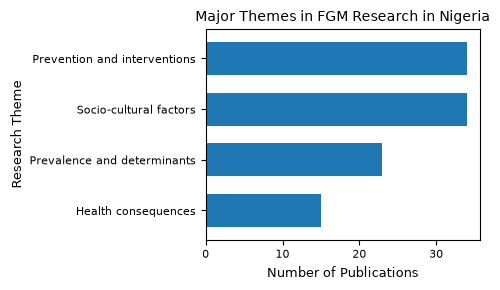

In [21]:
plt.figure(figsize=(5,3))

theme_counts.sort_values().plot(
    kind="barh",
    width=0.65
)

plt.title("Major Themes in FGM Research in Nigeria", fontsize=10)
plt.xlabel("Number of Publications", fontsize=9)
plt.ylabel("Research Theme", fontsize=9)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

plt.tight_layout()
plt.show()

### Interpretation

The chart presents the major themes identified in the included FGM publications.

Because a publication can address more than one research theme, the total number of theme assignments may be greater than the number of included publications.

The distribution will help identify whether socio-cultural factors and prevention-related research receive more attention than other themes.

The keyword-based approach is an initial classification method. Some publications may discuss a theme without using the selected keywords, while others may contain keywords without making that theme their main focus.

Therefore, the classifications should be manually reviewed against the titles and abstracts before the findings are treated as final.

## Summary of Findings

This section brings together the findings from the four research questions.

The analysis examined:

1. Publication trends: The annual distribution of FGM research publications between 2015 and 2026.

2. Geographical distribution: The geopolitical zones explicitly represented in the included studies, while keeping national, multi-country, and unspecified locations separate.

3. Research methodologies: The distribution of quantitative, qualitative, mixed-methods, and literature review publications.

4. Research themes: The recurring themes identified from the titles and abstracts of included publications.

The findings provide an overview of the research attention given to FGM in Nigeria during the study period.